### Check for Duplicates in the Dataset based on the MARC file






## Setup

In [ ]:
import os                      
import random   
import numpy as np   
import pandas as pd 
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image 

In [ ]:
base_dir = str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists()))  # repo root

img_root = os.path.join(base_dir, "data/ecommons/final_maps/Bax_LiteratureMaps_final_maps/final_maps")
labels_csv = os.path.join(base_dir, "data/ecommons/Gemini/Bax_LiteratureMaps_Gemini/Gemini_fict-scale_full.csv")
marc_csv = os.path.join(base_dir, "data/ecommons/MARC/Bax_LiteratureMaps_MARC/MARC_info_parallel.csv")

scale_names = {0: "Small (0)", 1: "Medium (1)", 2: "Large (2)"}

In [3]:
labels_data = pd.read_csv(labels_csv)
marc_data = pd.read_csv(marc_csv)

print("Label num rows:", len(labels_data))
print("Book data num rows:", len(marc_data))

Label num rows: 2622
Book data num rows: 89914


## Format of HTID
HTID is the file format (source: https://www.loc.gov/marc/umb/um01to06.html, https://www.hathitrust.org/member-libraries/resources-for-librarians/data-resources/hathifiles/hathifiles-description/)

Ex: obj/mdp/pairtree_root/39/01/50/02/71/23/08/39015002712308

The important parts are bolded: 

- obj/**mdp**/pairtree_root/39/01/50/02/71/23/08/39015002712308 -> library code
- obj/mdp/pairtree_root/39/01/50/02/71/23/08/**39015002712308** -> book ID

They don't always look like this, sometimes they look like: obj/loc/pairtree_root/ar/k+/=1/39/60/=t/19/k4/z2/0q/ark+=13960=t19k4z20q
- obj/**loc**/pairtree_root/ar/k+/=1/39/60/=t/19/k4/z2/0q/ark+=13960=t19k4z20q -> library code (unlisted in this case)
- obj/loc/pairtree_root/ar/k+/=1/39/60/=t/19/k4/z2/0q/**ark+=13960=t19k4z20q** -> book ID

For this book ID (ark+=13960=t19k4z20q), it's chopped up into different pieces and uses Pairtree to replace characters that can't be in folder names. In Pairtree, '+' means ':' and '=' means '/'. 
This means the book ID is actually: ark:/13960/t19k4z20q
- ark: means Archival Resource Key
- 13960 means the organization that made the key
- t19k4z20q means the code for that specific book 

We'll handle parsing this later. 

Need to pull the library code and book ID for every book

In [4]:
marc_clean = pd.DataFrame()

# Add in columns in the marc_clean for the library the book is from and the book ID
marc_clean["book_id"] = marc_data["htid"].str.split("/").str[-1] #split the htid field and take the last index as the book id
marc_clean["library"] = marc_data["htid"].str.split("/").str[1] #take the second index as the library code

## Renaming Columns in MARC dataset

The columns in the MARC file represent the following data:
- _250_a -> Edition statemen
- _260_b -> Name of publisher, distributor, etc.
- _260_a -> Place of publication, distribution, etc.
- _260_c -> Date of publication, distribution, etc.
- _245_a -> Title
- _245_c -> Statement of responsibility, etc. 
- _100_a -> Personal name (Author)
- _100_d -> Dates associated with a name
- _300_a -> Physical Description (Extent)
- _300_b -> Other physical details
- _300_c -> Dimensions
- _500_a -> General note
- _651_v -> Subject Added Entry-Geographic Name (Form subdivision)
- page_count -> page count 

Source: https://www.loc.gov/marc/bibliographic/

The important ones for checking for duplicates are: 
- _245_a -> Title
- _100_a -> Personal name (Author)
- _260_b -> Name of publisher, distributor, etc.
- _260_c -> Date of publication, distribution, etc.



In [5]:
# Write title, author, publisher, and year into the marc_clean dataframe

marc_clean["title"] = marc_data["_245_a"]
marc_clean["author"] = marc_data["_100_a"]
marc_clean["publisher"] = marc_data["_260_b"]
marc_clean["year"] = marc_data["_260_c"]

In [6]:
# Check to make sure the dataframe looks reasonable

marc_clean.head(10)

,book_id,library,title,author,publisher,year
0,ark+=13960=t19k4z20q,loc,Selections from American authors.,"Eliot, Samuel,","Taintor Brothers, Merrill & Co.",[1879]
1,ark+=13960=t19k4vg58,loc,"The bride of Fort Edward,","Bacon, Delia Salter,","Published by S. Colman,",1839.
2,ark+=13960=t6vx0w58c,loc,"Prose fancies,","Le Gallienne, Richard,","G.P. Putnam's sons; [etc., etc.]",1894.
3,ark+=13960=t6vx0w74b,loc,Letters received in my two widow-hoods ...,"[Gibson, Horton John] [from old catalog]",Myrtle publishing company,[1896]
4,ark+=13960=t6vx0pt9w,loc,Old-time child-life.,"[Rollins, Ellen Chapman (Hobbs)]","J. B. Lippincott & co.,",1881.
5,ark+=13960=t0dv2774v,loc,"The new book of martyrs,","Duhamel, Georges,",George H. Doran company,[c1918]
6,ark+=13960=t0dv23v67,loc,Their hearts' desire /,"Perry, Frances Foster.","Dodd, Mead & Company,",1909.
7,ark+=13960=t0dv1nw5f,loc,The Pawnee mythology (part I),"Dorsey, George Amos,","The Carnegie institution of Washington,",1906.
8,ark+=13960=t61558p6j,loc,Outwitting the Hun;,"O'Brien, Pat,",Harper & brothers,[c1918]
9,ark+=13960=t61554r3b,loc,"The idle thoughts of an idle fellow,","Jerome, Jerome K.","H. Holt,",1890.


In [ ]:
# Check where I have any NaNs
print(marc_clean.isna().sum())

book_id         0
library         0
title          52
author       3043
publisher    2692
year         2196
dtype: int64


## Clean up labels_data ##

I need to clean up the labels dataframe so that I can join the marc_clean dataframe with it based on book ID

Currently, the book IDs are saved in the "Image" column like: final_maps/**000000606028**_00000061.jpg, where the book ID that I need is bolded. I need to strip the "final_maps/" part of it and then split the string and take the first index. 

In [12]:
labels_data.head(10)

,Fictionality,Explanation_fict,Image,Scale,Explanation_scale
0,real,"The map depicts real places like Virginia, Nor...",final_maps/000000606028_00000061.jpg,2,"The map shows a large area, including regions ..."
1,fictional,"This map is from the novel Tom Sawyer Abroad, ...",final_maps/000001112276_00000151.jpg,0,"The map shows the floor plan of a house, inclu..."
2,real,The map is labeled as 'Map of Paris' and conta...,final_maps/000001112276_00000485.jpg,1,The map shows a settlement. Individual buildin...
3,fictional,The map features locations like the 'Sea of Dr...,final_maps/000005315321_00000418.jpg,2,"The map depicts a large region of Africa, show..."
4,fictional,"The map contains names like 'KLUCHI', 'CHORNY'...",final_maps/000006082062_00000002.jpg,2,"The map depicts a region, showing features lik..."
5,fictional,"The map contains elements like 'Burnt Cabin,' ...",final_maps/000006082062_00000003.jpg,2,"The map depicts a large area with mountains, l..."
6,fictional,The map contains locations such as 'Gorbitza' ...,final_maps/000006082062_00000360.jpg,2,"The map depicts a large area, specifically the..."
7,fictional,"The map appears to be fictional, as indicated ...",final_maps/000006082062_00000361.jpg,2,The map depicts a region with towns and landma...
8,fictional,The map contains fictional locations such as '...,final_maps/000006180300_00000182.jpg,2,"The map depicts a large area, likely a region ..."
9,real,"The map depicts real continents and oceans, ev...",final_maps/000018640427_00000024.jpg,1,The map shows a city or town. Individual build...


In [15]:
filenames = labels_data["Image"].str.replace("final_maps/", "")
# print(filenames)
labels_data["book_id"] = filenames.str.split("_").str[0]
labels_data.head(10)

,Fictionality,Explanation_fict,Image,Scale,Explanation_scale,book_id
0,real,"The map depicts real places like Virginia, Nor...",final_maps/000000606028_00000061.jpg,2,"The map shows a large area, including regions ...",000000606028
1,fictional,"This map is from the novel Tom Sawyer Abroad, ...",final_maps/000001112276_00000151.jpg,0,"The map shows the floor plan of a house, inclu...",000001112276
2,real,The map is labeled as 'Map of Paris' and conta...,final_maps/000001112276_00000485.jpg,1,The map shows a settlement. Individual buildin...,000001112276
3,fictional,The map features locations like the 'Sea of Dr...,final_maps/000005315321_00000418.jpg,2,"The map depicts a large region of Africa, show...",000005315321
4,fictional,"The map contains names like 'KLUCHI', 'CHORNY'...",final_maps/000006082062_00000002.jpg,2,"The map depicts a region, showing features lik...",000006082062
5,fictional,"The map contains elements like 'Burnt Cabin,' ...",final_maps/000006082062_00000003.jpg,2,"The map depicts a large area with mountains, l...",000006082062
6,fictional,The map contains locations such as 'Gorbitza' ...,final_maps/000006082062_00000360.jpg,2,"The map depicts a large area, specifically the...",000006082062
7,fictional,"The map appears to be fictional, as indicated ...",final_maps/000006082062_00000361.jpg,2,The map depicts a region with towns and landma...,000006082062
8,fictional,The map contains fictional locations such as '...,final_maps/000006180300_00000182.jpg,2,"The map depicts a large area, likely a region ...",000006180300
9,real,"The map depicts real continents and oceans, ev...",final_maps/000018640427_00000024.jpg,1,The map shows a city or town. Individual build...,000018640427


## Merge labels_data and MARC_data ##

Need to merge the tables so that each entry in the labels_data gets the corresponding MARC data, so will use how = "left" in the merge function

In [16]:
merged = labels_data.merge(marc_clean, on="book_id", how="left")

In [18]:
merged.head(10)

,Fictionality,Explanation_fict,Image,Scale,Explanation_scale,book_id,library,title,author,publisher,year
0,real,"The map depicts real places like Virginia, Nor...",final_maps/000000606028_00000061.jpg,2,"The map shows a large area, including regions ...",000000606028,pst,Horse-Shoe Robinson /,"Kennedy, John Pendleton,","American Book Company,",c1937.
1,fictional,"This map is from the novel Tom Sawyer Abroad, ...",final_maps/000001112276_00000151.jpg,0,"The map shows the floor plan of a house, inclu...",000001112276,pst,Stormfield edition of the writings of Mark Twa...,"Twain, Mark,","Harper,",1929].
2,real,The map is labeled as 'Map of Paris' and conta...,final_maps/000001112276_00000485.jpg,1,The map shows a settlement. Individual buildin...,000001112276,pst,Stormfield edition of the writings of Mark Twa...,"Twain, Mark,","Harper,",1929].
3,fictional,The map features locations like the 'Sea of Dr...,final_maps/000005315321_00000418.jpg,2,"The map depicts a large region of Africa, show...",000005315321,pst,Works.,"Kipling, Rudyard,","Century Co.,",1899.
4,fictional,"The map contains names like 'KLUCHI', 'CHORNY'...",final_maps/000006082062_00000002.jpg,2,"The map depicts a region, showing features lik...",000006082062,pst,Siberian gold /,"Harper, Theodore Acland,","Doubleday, Page & company,",1927.
5,fictional,"The map contains elements like 'Burnt Cabin,' ...",final_maps/000006082062_00000003.jpg,2,"The map depicts a large area with mountains, l...",000006082062,pst,Siberian gold /,"Harper, Theodore Acland,","Doubleday, Page & company,",1927.
6,fictional,The map contains locations such as 'Gorbitza' ...,final_maps/000006082062_00000360.jpg,2,"The map depicts a large area, specifically the...",000006082062,pst,Siberian gold /,"Harper, Theodore Acland,","Doubleday, Page & company,",1927.
7,fictional,"The map appears to be fictional, as indicated ...",final_maps/000006082062_00000361.jpg,2,The map depicts a region with towns and landma...,000006082062,pst,Siberian gold /,"Harper, Theodore Acland,","Doubleday, Page & company,",1927.
8,fictional,The map contains fictional locations such as '...,final_maps/000006180300_00000182.jpg,2,"The map depicts a large area, likely a region ...",000006180300,pst,The novels and stories.,"Stockton, Frank Richard,","Scribner,",1899-1904.
9,real,"The map depicts real continents and oceans, ev...",final_maps/000018640427_00000024.jpg,1,The map shows a city or town. Individual build...,000018640427,pst,Health readers ... /,"Lummis, Jessie L.",NaN,[c1927-1932].


## Find Duplicates ##

A book ID may be repeated if there are multiple maps in that book, so those should be left alone (ex. 000006082062_00000002.jpg and 000006082062_00000003.jpg are two different maps from the same book).

Two books from different libraries (or even the same library) will have different book IDs usually, so need to match them based on the author's name and title. 
I'm worried that different libraries may use different capitalization and punctuation, so I'm going to strip that from the authors and titles and standardize the NaN cells to be blank (AKA ""). 

In [21]:
def clean(col):
    allowed_characters = "abcdefghijklmnopqrstuvwxyz0123456789 " #all letters, numbers, and space

    cleaned_column = []

    for value in col:
        #if NaN: Empty cells (NaN) become an empty string
        if pd.isna(value):
            cleaned_column.append("")
            continue # go to next row

        #since not NaN, make it lowercase
        value = value.lower() 

        # Make sure the text only contains the allowed characters (no punctuation)
        cleaned_text = ""
        for character in value:
            if character in allowed_characters:     # keep letters, digits, and spaces
                cleaned_text = cleaned_text + character # anything else (punctuation, brackets, slashes) is skipped

        cleaned_text = cleaned_text.strip() # remove spaces at the start and end
        cleaned_column.append(cleaned_text)

    return cleaned_column

In [ ]:
# Create key we'll use to check titles and authors
titles = pd.Series(clean(merged["title"]),index= merged.index) # paranoid about re-indexing so I added the index arg when I made it into a pd Series haha
authors = pd.Series(clean(merged["author"]),index= merged.index)
merged["title_author_key"] = titles + " + " + authors # save this key "title+author" that we'll use to check if the same key came from different libraries

In [31]:
# Check how many book IDs each "title|author" key has

book_id_by_key = merged.groupby("title_author_key")["book_id"].nunique()

print("Number of different books:", merged["book_id"].nunique())
print("Number of different title|author works: ", merged["title_author_key"].nunique())
print("Number of works with 2+ copies:   ", (book_id_by_key > 1).sum())

# show the top 10 most duplicated works
book_id_by_key.sort_values(ascending=False).head(10)

Number of different books: 1557
Number of different title|author works:  900
Number of works with 2+ copies:    286


title_author_key
treasure island + stevenson robert louis                                   23
travels into several remote nations of the world + swift jonathan          18
works + hardy thomas                                                       16
the novels and tales of robert louis stevenson + stevenson robert louis    15
the days work + kipling rudyard                                            15
with clive in india or the beginnings of an empire + henty g a             14
true to the old flag + henty g a                                           13
one of the 28th + henty g a                                                12
the writings of mark twain pseud + twain mark                              11
the writings of mark twain + twain mark                                    11
Name: book_id, dtype: int64

In [ ]:
def show_work(work):
    # Each ROW is one scanned copy (book_id); each COLUMN is one map from that copy.

    # Gget all images for this work
    images = merged[merged["title_author_key"] == work]
    # list ALL the different book IDs
    copies = images["book_id"].unique()
    num_rows = len(copies) # ex. 23 for Treasure Island

    #find the copy with the most maps for the number of columns
    maps_per_copy = images["book_id"].value_counts()# maps in each copy
    num_cols = maps_per_copy.max()

    print(f"{work}: {num_rows} copies, max maps per copy: {num_cols}")

    # Make an empty grid of subplots
    fig, axes = plt.subplots(num_rows, num_cols,figsize=(3 * num_cols, 3.5 * num_rows),squeeze=False) #It took forever to troubleshoot this line because I kept getting an error if I didn't have squeeze=False. 
                                                                                                      #If a book only has 1 map, it won't be a list, and won't work on a 2D grid (based on the way I'm indexing), so squeeze forces the dimensions to work.

    #Fill in the grid. Each row = each copy
    for row in range(num_rows):
        book = copies[row]
        # All images from this copy
        book_images = images[images["book_id"] == book]
        book_images = book_images.sort_values("Image") #want it to be in order (ex the first map from the book is the first image in the row, etc. based on filename)

        for col in range(num_cols):
            ax = axes[row, col]
            ax.axis("off") # hide tick marks
            # leave the plot empty if this copy doesn't have the max number of images (ex. copy 1 has 4 pics from treasure island vs. copy 2 has 2 pics from treasure island)
            if col >= len(book_images):
                continue

            # Pull out the info for the subplot title
            image_info = book_images.iloc[col]
            filename = image_info["Image"].replace("final_maps/", "") #strip out the final_maps/
            library = image_info["library"]
            key = image_info["title_author_key"]

            # Open the image and shrink it, otherwise it was too big to scroll through when I tried
            img = Image.open(os.path.join(img_root, filename))
            img.thumbnail((300, 300)) #just do a small image, not the entire one
            ax.imshow(img)
            ax.set_title(f"{filename}\nlibrary: {library}\n{key}", fontsize=6)


travels into several remote nations of the world + swift jonathan: 18 copies, max maps per copy: 5


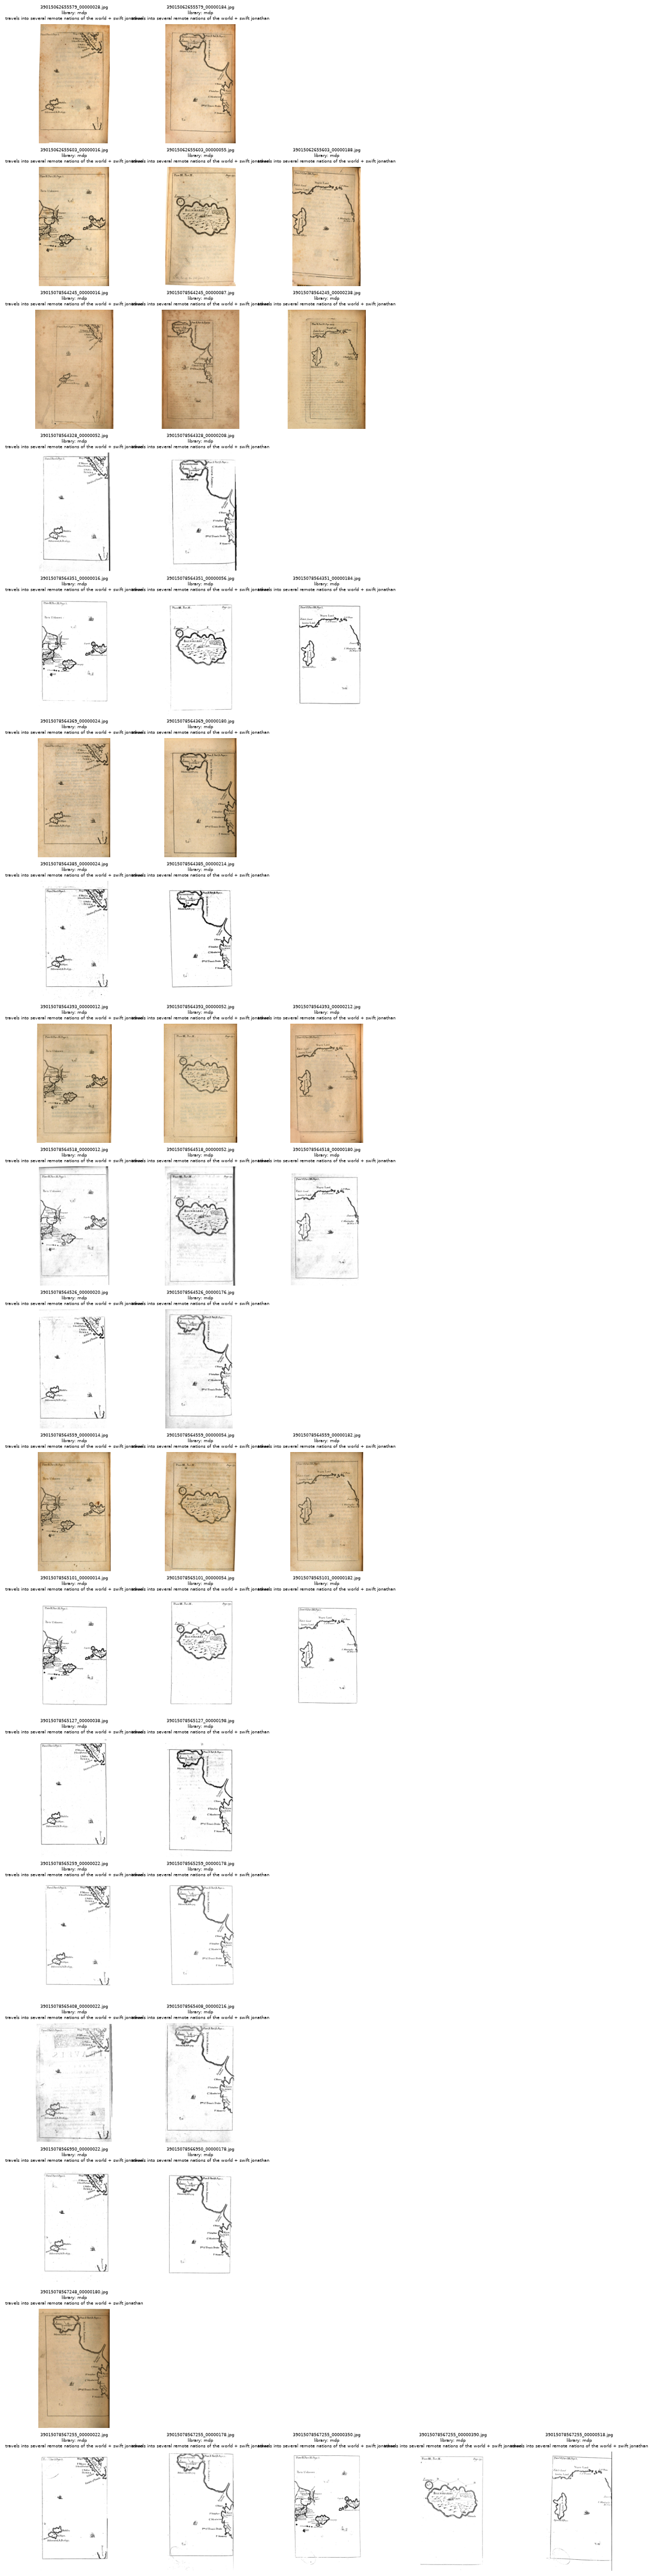

In [54]:
show_work("travels into several remote nations of the world + swift jonathan")